# Seleção de ofertas em campanhas de marketing direto

Implementação dos modelos M1/M2 e do set covering M3 do problema descrito por Talla Nobibon, Leus e Spieksma (2011). O código reutilizável está nos módulos deste projeto; execute o notebook a partir da pasta do repositório, após instalar as dependências com `python -m pip install -e ".[test,plots]"`.

O exemplo reproduz os valores especificados, resolve as formulações com HiGHS, compara as relaxações lineares e confere o ótimo por enumeração independente. O gerador segue a Secção 5.1, com o teto de MQC ajustado para `floor(2 ΣM_i/n)` para evitar intervalos impossíveis de orçamento; a variante aleatória de orçamento usa o limite superior corrigido descrito em `generator.py`. Custos fixos fora de um intervalo inteiro admissível geram aviso e usam `max(0, ceil(limite inferior))`.

In [1]:
%pip install -e ".[test,plots]"

Defaulting to user installation because normal site-packages is not writeable
Obtaining file:///D:/git/paper-optimization-models-for-targeted-offers-in-direct-marketing
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for direct-marketing-offer-optimization (pyproject.toml): started
  Building editable for direct-marketing-offer-optimization (pyproject.toml): finished with status 'done'
  Created wheel for direct-marketing-offer-optimization: filename=direct_marketing_offer_optimization-0.1.0-0.editable-py3-none-any.whl size=32


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\judec\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
from instance import validation_instance
from models import brute_force_optimum, solve_model
from setcover import enumerate_columns, solve_setcover

instance = validation_instance()
print(f"Clientes: {instance.m}; produtos: {instance.n}; R: {instance.hurdle_rate:.2f}")

Clientes: 3; produtos: 2; R: 0.10


In [3]:
columns = enumerate_columns(instance)
print(f"Colunas admissíveis: {len(columns)} de 14 conjuntos candidatos não vazios")
for column in columns:
    product = instance.product_names[column.product]
    customers = tuple(i + 1 for i in column.customers)
    print(f"{product} {customers}: lucro={column.objective_coefficient:g}, hurdle={column.hurdle_coefficient:.1f}")

Colunas admissíveis: 8 de 14 conjuntos candidatos não vazios
A (1, 2): lucro=9, hurdle=8.5
A (1, 3): lucro=10, hurdle=9.4
B (1,): lucro=2, hurdle=1.8
B (2,): lucro=1, hurdle=0.8
B (3,): lucro=1, hurdle=0.7
B (1, 2): lucro=4, hurdle=3.7
B (1, 3): lucro=4, hurdle=3.6
B (2, 3): lucro=3, hurdle=2.6


In [4]:
brute_value, brute_x, brute_y, optimum_count = brute_force_optimum(instance)
print(f"Ótimo por força bruta: {brute_value:g}; soluções ótimas: {optimum_count}")
print("x (linhas=clientes, colunas=A/B):")
for row in brute_x:
    print(row)
print("y:", brute_y)
assert brute_value == 11 and optimum_count == 1

Ótimo por força bruta: 11; soluções ótimas: 1
x (linhas=clientes, colunas=A/B):
(1.0, 0.0)
(0.0, 1.0)
(1.0, 0.0)
y: (1.0, 1.0)


In [5]:
integer_results = {
    "M1": solve_model(instance, "M1"),
    "M2": solve_model(instance, "M2"),
    "M3": solve_setcover(instance),
}
for name, result in integer_results.items():
    print(f"{name}: objetivo={result.objective:g}; estado={result.termination}; tempo={result.elapsed_seconds:.3f}s")
    assert result.objective == 11

M1: objetivo=11; estado=optimal; tempo=0.041s
M2: objetivo=11; estado=optimal; tempo=0.039s
M3: objetivo=11; estado=optimal; tempo=0.049s


In [6]:
lp_values = {
    "M1": solve_model(instance, "M1", relax=True).objective,
    "M2": solve_model(instance, "M2", relax=True).objective,
    "M3": solve_setcover(instance, relax=True).objective,
}
print("Limites LP:", ", ".join(f"{name}={value:.6f}" for name, value in lp_values.items()))
assert 11 <= lp_values["M3"] + 1e-7 <= lp_values["M2"] + 1e-7 <= lp_values["M1"] + 1e-7

Limites LP: M1=12.888889, M2=12.666667, M3=11.000000


In [7]:
from generator import generate_budget_variants

small_instances = generate_budget_variants(
    m=100, n=5, hurdle_rate=0.10, capacity_variant="s", seed=2026
)
for budget_type, generated in small_instances.items():
    print(
        f"{budget_type}: {generated.m} clientes, {generated.n} produtos, "
        f"orçamentos={generated.budgets}, custos fixos={generated.fixed_costs}"
    )

# Geração do plano experimental (162 instâncias por padrão):
# python generator.py --output-dir instances --seed 1
# Resolução M1/M2 e relatórios CSV:
# python run_experiments.py --instances-dir instances

minimum: 100 clientes, 5 produtos, orçamentos=(64.0, 46.0, 81.0, 65.0, 85.0), custos fixos=(147.0, 93.0, 158.0, 116.0, 168.0)
maximum: 100 clientes, 5 produtos, orçamentos=(81.0, 77.0, 84.0, 87.0, 86.0), custos fixos=(147.0, 93.0, 158.0, 116.0, 168.0)
random: 100 clientes, 5 produtos, orçamentos=(81.0, 71.0, 82.0, 84.0, 86.0), custos fixos=(147.0, 93.0, 158.0, 116.0, 168.0)


## Experimento S1: comparação entre solvers

As próximas células geram as 54 instâncias S1 (m=100: 3 valores de n × 3 taxas R × 2 variantes de M × 3 orçamentos), resolvem M1 e M2 com HiGHS, Gurobi e CPLEX e salvam resultados detalhados em `results/S1_results.csv` e agregados em `results/S1_aggregate.csv`. Para cada combinação solver/instância/modelo são executadas a resolução inteira e a relaxação LP. A duração depende do equipamento e das licenças; configure `TIME_LIMIT_SECONDS` antes de iniciar. Nenhum solver indisponível será ignorado silenciosamente.

In [8]:
from pathlib import Path
from generator import generate_budget_variants

SEED = 1
S1_DIR = Path("instances") / "S1"
S1_DIR.mkdir(parents=True, exist_ok=True)
S1_INSTANCE_PATHS = []

for n in (5, 10, 15):
    for hurdle_rate in (0.05, 0.10, 0.15):
        for capacity_variant in ("s", "l"):
            variants = generate_budget_variants(
                m=100,
                n=n,
                hurdle_rate=hurdle_rate,
                capacity_variant=capacity_variant,
                seed=SEED,
            )
            for budget_variant, generated in variants.items():
                path = S1_DIR / (
                    f"S1_n{n}_R{hurdle_rate * 100:.0f}_"
                    f"{capacity_variant}_{budget_variant}_seed{SEED}.json"
                )
                generated.to_json(path)
                S1_INSTANCE_PATHS.append(path)

assert len(S1_INSTANCE_PATHS) == 54
print(f"S1: {len(S1_INSTANCE_PATHS)} instâncias geradas em {S1_DIR.resolve()}")

S1: 54 instâncias geradas em D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\instances\S1


In [9]:
import pyomo.environ as pyo

S1_SOLVERS = ("appsi_highs", "gurobi", "cplex")
unavailable = [
    solver
    for solver in S1_SOLVERS
    if not pyo.SolverFactory(solver).available(exception_flag=False)
]
if unavailable:
    raise RuntimeError(
        "Configure os seguintes solvers antes de executar o experimento: "
        + ", ".join(unavailable)
    )
print("Solvers disponíveis para o S1:", ", ".join(S1_SOLVERS))

Solvers disponíveis para o S1: appsi_highs, gurobi, cplex


In [10]:
from run_experiments import (
    run_experiments,
    write_aggregate_report,
    write_results_csv,
)

TIME_LIMIT_SECONDS = 3600
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
S1_RESULTS = []

for solver_name in S1_SOLVERS:
    print(f"Executando S1 com {solver_name}...")
    solver_rows = run_experiments(
        S1_INSTANCE_PATHS,
        RESULTS_DIR / f"S1_{solver_name}.csv",
        solver=solver_name,
        time_limit=TIME_LIMIT_SECONDS,
        progress=True,
    )
    S1_RESULTS.extend(solver_rows)

S1_RESULTS_PATH = RESULTS_DIR / "S1_results.csv"
S1_AGGREGATE_PATH = RESULTS_DIR / "S1_aggregate.csv"
write_results_csv(S1_RESULTS, S1_RESULTS_PATH)
S1_AGGREGATE = write_aggregate_report(S1_RESULTS, S1_AGGREGATE_PATH)
print(
    f"Concluído: {len(S1_RESULTS)} linhas detalhadas; "
    f"arquivos consolidados em {RESULTS_DIR.resolve()}"
)

Executando S1 com appsi_highs...
[appsi_highs] 1/54 concluída: S1_n5_R5_s_minimum_seed1.json
[appsi_highs] 2/54 concluída: S1_n5_R5_s_maximum_seed1.json
[appsi_highs] 3/54 concluída: S1_n5_R5_s_random_seed1.json
[appsi_highs] 4/54 concluída: S1_n5_R5_l_minimum_seed1.json
[appsi_highs] 5/54 concluída: S1_n5_R5_l_maximum_seed1.json
[appsi_highs] 6/54 concluída: S1_n5_R5_l_random_seed1.json
[appsi_highs] 7/54 concluída: S1_n5_R10_s_minimum_seed1.json
[appsi_highs] 8/54 concluída: S1_n5_R10_s_maximum_seed1.json
[appsi_highs] 9/54 concluída: S1_n5_R10_s_random_seed1.json
[appsi_highs] 10/54 concluída: S1_n5_R10_l_minimum_seed1.json
[appsi_highs] 11/54 concluída: S1_n5_R10_l_maximum_seed1.json
[appsi_highs] 12/54 concluída: S1_n5_R10_l_random_seed1.json
[appsi_highs] 13/54 concluída: S1_n5_R15_s_minimum_seed1.json
[appsi_highs] 14/54 concluída: S1_n5_R15_s_maximum_seed1.json
[appsi_highs] 15/54 concluída: S1_n5_R15_s_random_seed1.json
[appsi_highs] 16/54 concluída: S1_n5_R15_l_minimum_seed1.

In [11]:
from statistics import mean, median

if not S1_RESULTS:
    raise RuntimeError("Execute primeiro a célula 'run-s1-solvers'.")

analysis_groups = defaultdict(list)
for row in S1_RESULTS:
    analysis_groups[(row["solver"], row["model"])].append(row)

print("Resumo geral por solver e modelo")
print(f"{'Solver':<14} {'Modelo':<7} {'Ótimos':>12} {'Gap LP médio':>15} {'Tempo mediano (s)':>20} {'Gap MIP médio':>15}")
for (solver_name, model_name), rows in sorted(analysis_groups.items()):
    optimal_count = sum(row["termination"].lower() == "optimal" for row in rows)
    lp_gaps = [float(row["lp_gap_percent"]) for row in rows if row["lp_gap_percent"] is not None]
    mip_gaps = [float(row["mip_gap_percent"]) for row in rows if row["mip_gap_percent"] is not None]
    times = [float(row["elapsed_seconds"]) for row in rows]
    print(
        f"{solver_name:<14} {model_name:<7} {optimal_count:>5}/{len(rows):<6} "
        f"{mean(lp_gaps) if lp_gaps else float('nan'):>14.3f}% "
        f"{median(times):>20.3f} "
        f"{mean(mip_gaps) if mip_gaps else float('nan'):>14.4f}%"
    )

print("\nDetalhe por tamanho de n (18 instâncias por n e por solver/modelo)")
print(f"{'Solver':<14} {'Modelo':<7} {'n':>3} {'Ótimos':>10} {'Gap LP médio':>15} {'Tempo médio (s)':>17}")
for key in sorted({(row['solver'], row['model'], row['n']) for row in S1_RESULTS}):
    solver_name, model_name, n_value = key
    rows = [row for row in S1_RESULTS if (row['solver'], row['model'], row['n']) == key]
    optimal_count = sum(row["termination"].lower() == "optimal" for row in rows)
    lp_gaps = [float(row["lp_gap_percent"]) for row in rows if row["lp_gap_percent"] is not None]
    times = [float(row["elapsed_seconds"]) for row in rows]
    print(
        f"{solver_name:<14} {model_name:<7} {n_value:>3} "
        f"{optimal_count:>4}/{len(rows):<5} "
        f"{mean(lp_gaps) if lp_gaps else float('nan'):>14.3f}% "
        f"{mean(times):>17.3f}"
    )

print("\nInterpretação: compare tempos e proporção de ótimos provados para avaliar desempenho do solver.")
print("Os gaps LP medem a força da formulação (M1/M2), não uma vantagem do solver; devem coincidir entre solvers, salvo tolerâncias numéricas.")
print("O gap MIP compara incumbent e bound quando a otimalidade não foi provada. Consulte os CSVs para estados por instância.")

comparable_cases = defaultdict(list)
for row in S1_RESULTS:
    if row["objective"] is not None and row["termination"].lower() == "optimal":
        comparable_cases[(row["instance"], row["model"])].append((row["solver"], float(row["objective"])))
fully_comparable_cases = {
    case: values for case, values in comparable_cases.items()
    if len(values) == len(S1_SOLVERS)
}
objective_mismatches = []
for case, values in fully_comparable_cases.items():
    if max(value for _, value in values) - min(value for _, value in values) > 1e-6:
        objective_mismatches.append((case, values))
print(
    f"\nConcordância de objetivos: {len(fully_comparable_cases) - len(objective_mismatches)} "
    f"de {len(fully_comparable_cases)} casos completos sem divergência; "
    f"{len(objective_mismatches)} divergências."
)
if objective_mismatches:
    print("Revise os casos divergentes nos CSVs detalhados:", objective_mismatches[:5])
print(f"Relatórios: {S1_RESULTS_PATH.resolve()} e {S1_AGGREGATE_PATH.resolve()}")

Resumo geral por solver e modelo
Solver         Modelo        Ótimos    Gap LP médio    Tempo mediano (s)   Gap MIP médio
appsi_highs    M1         54/54             44.362%                5.676         0.0000%
appsi_highs    M2         54/54              1.179%                1.066         0.0000%
cplex          M1         54/54             44.362%                0.680         0.0000%
cplex          M2         54/54              1.179%                0.354         0.0000%
gurobi         M1         54/54             44.362%                0.344         0.0000%
gurobi         M2         54/54              1.179%                0.199         0.0000%

Detalhe por tamanho de n (18 instâncias por n e por solver/modelo)
Solver         Modelo    n     Ótimos    Gap LP médio   Tempo médio (s)
appsi_highs    M1        5   18/18            40.079%             2.230
appsi_highs    M1       10   18/18            47.761%            11.924
appsi_highs    M1       15   18/18            45.246%       

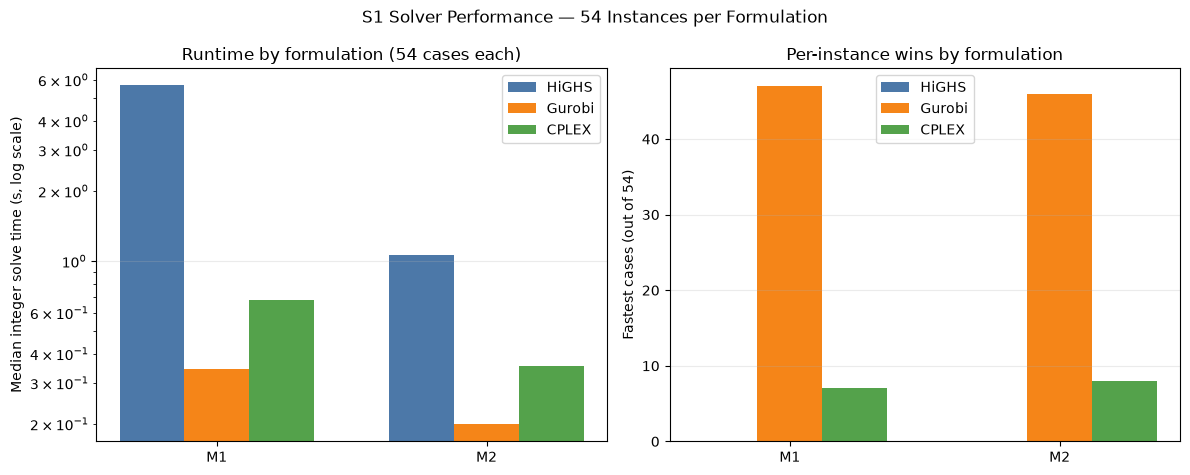

Tempos medianos gerais (segundos):
M1 {'HiGHS': 5.676, 'Gurobi': 0.344, 'CPLEX': 0.68}
M2 {'HiGHS': 1.066, 'Gurobi': 0.199, 'CPLEX': 0.354}
Vitórias gerais (empates contam para cada solver empatado):
M1 {'HiGHS': 0, 'Gurobi': 47, 'CPLEX': 7}
M2 {'HiGHS': 0, 'Gurobi': 46, 'CPLEX': 8}

Detalhamento por N e formulação (18 instâncias por grupo)
  N Modelo  Solver       Média (s)   Mediana (s)   Vitórias/18  Solver/Gurobi  Solver/CPLEX
  5 M1      HiGHS            2.230         0.747      0/18          8.15x         2.62x
  5 M1      Gurobi           0.105         0.087     18/18          1.00x         0.38x
  5 M1      CPLEX            0.305         0.274      0/18          2.64x         1.00x
  5 M2      HiGHS            2.212         0.217      0/18          2.68x         1.14x
  5 M2      Gurobi           0.104         0.089     18/18          1.00x         0.36x
  5 M2      CPLEX            0.330         0.310      0/18          2.74x         1.00x
 10 M1      HiGHS           11.924   

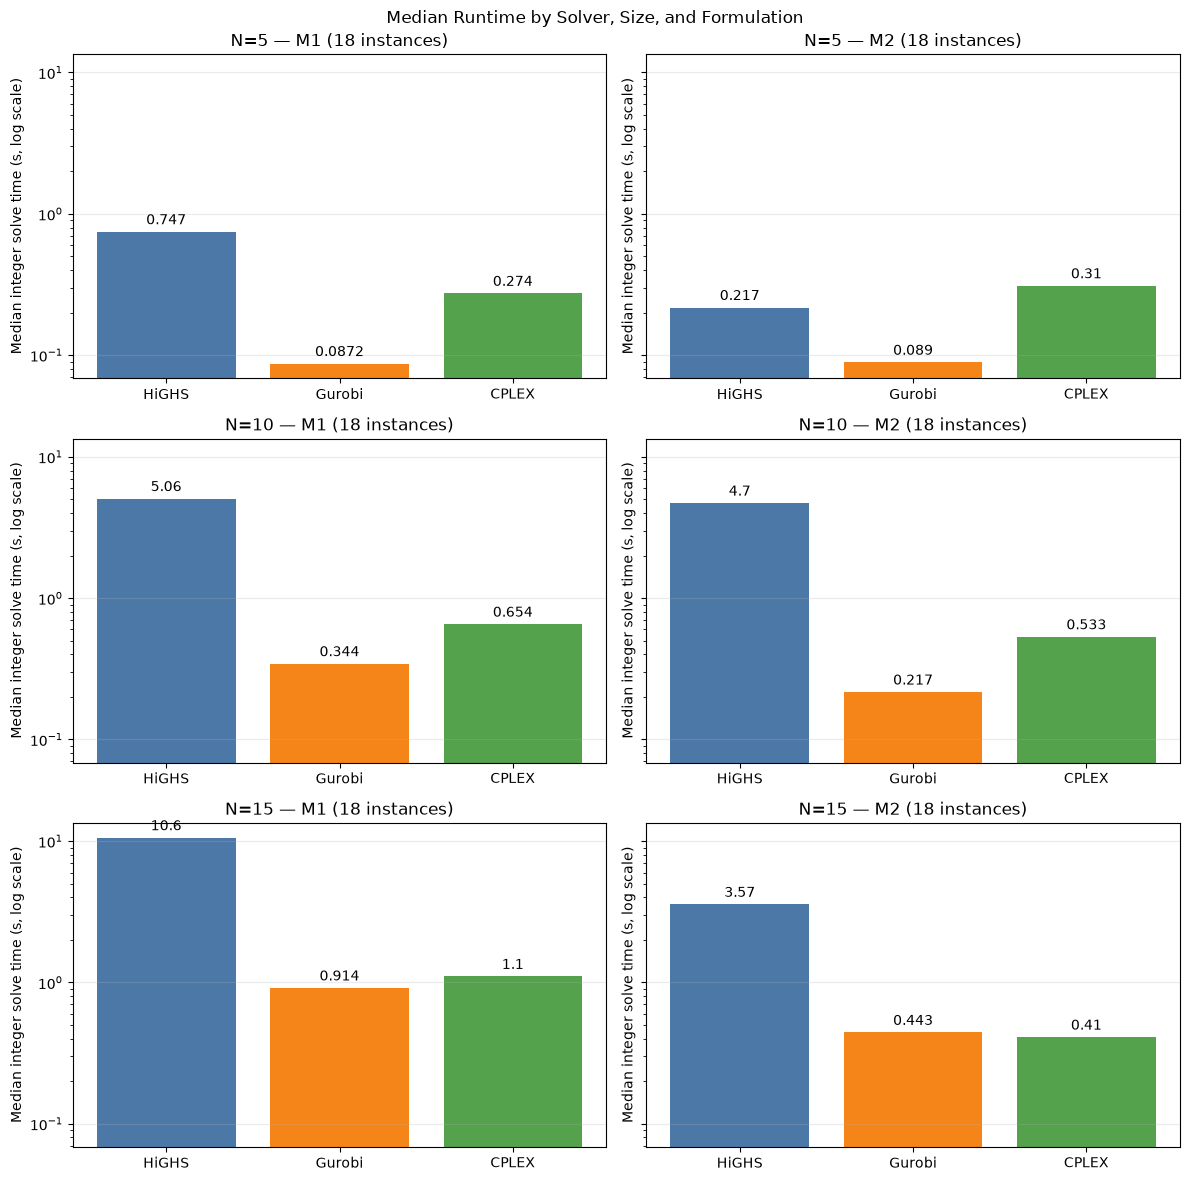

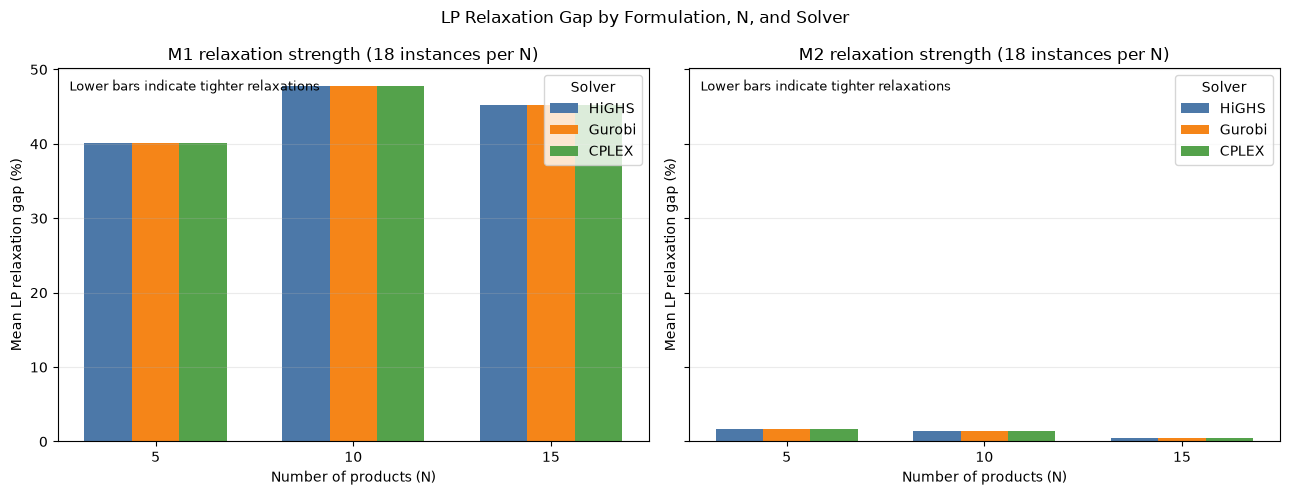

Mean LP relaxation gap by N and formulation (lower is better):
M1, N=5: 40.0793% (solver spread 1.42e-14 percentage points)
M1, N=10: 47.7607% (solver spread 4.26e-14 percentage points)
M1, N=15: 45.2465% (solver spread 1.42e-14 percentage points)
M2, N=5: 1.7434% (solver spread 1.40e-14 percentage points)
M2, N=10: 1.3871% (solver spread 3.24e-14 percentage points)
M2, N=15: 0.4055% (solver spread 3.43e-14 percentage points)
Solver bars are grouped side by side. Equal heights mean the solvers returned the same LP relaxation value; formulation changes the relaxation strength.
Charts saved to D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\results\plots\S1_solver_runtime.png, D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\results\plots\S1_solver_runtime_by_n_model.png, and D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\results\plots\S1_lp_relaxation_gap_by_solver.png


In [12]:
from collections import Counter, defaultdict
from math import isclose
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt

if not S1_RESULTS:
    raise RuntimeError("Execute primeiro a célula 'run-s1-solvers'.")

solver_order = ("appsi_highs", "gurobi", "cplex")
solver_labels = {"appsi_highs": "HiGHS", "gurobi": "Gurobi", "cplex": "CPLEX"}
solver_colors = {"appsi_highs": "#4C78A8", "gurobi": "#F58518", "cplex": "#54A24B"}
runtime_groups = defaultdict(list)
lp_gap_groups = defaultdict(list)
results_by_case = defaultdict(list)
for row in S1_RESULTS:
    runtime_groups[(row["solver"], row["model"])].append(float(row["elapsed_seconds"]))
    lp_gap_groups[(row["solver"], int(row["n"]), row["model"])].append(float(row["lp_gap_percent"]))
    results_by_case[(row["instance"], row["model"])].append(row)
    runtime_groups[(row["solver"], int(row["n"]), row["model"])].append(float(row["elapsed_seconds"]))

output_dir = Path("results") / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
model_order = ("M1", "M2")
bar_width = 0.24
for solver_index, solver_name in enumerate(solver_order):
    medians = [median(runtime_groups[(solver_name, model)]) for model in model_order]
    positions = [index + (solver_index - 1) * bar_width for index in range(len(model_order))]
    axes[0].bar(
        positions,
        medians,
        width=bar_width,
        label=solver_labels[solver_name],
        color=solver_colors[solver_name],
    )
axes[0].set_yscale("log")
axes[0].set_xticks(range(len(model_order)), model_order)
axes[0].set_ylabel("Median integer solve time (s, log scale)")
axes[0].set_title("Runtime by formulation (54 cases each)")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()

fastest_counts = Counter()
for case_key, rows in results_by_case.items():
    if len(rows) != len(solver_order):
        continue
    best_time = min(float(row["elapsed_seconds"]) for row in rows)
    for row in rows:
        if isclose(float(row["elapsed_seconds"]), best_time, rel_tol=1e-9, abs_tol=1e-9):
            fastest_counts[(row["solver"], row["model"])] += 1
            fastest_counts[(row["solver"], int(row["n"]), row["model"])] += 1

for solver_index, solver_name in enumerate(solver_order):
    counts = [fastest_counts[(solver_name, model)] for model in model_order]
    positions = [index + (solver_index - 1) * bar_width for index in range(len(model_order))]
    axes[1].bar(
        positions,
        counts,
        width=bar_width,
        label=solver_labels[solver_name],
        color=solver_colors[solver_name],
    )
axes[1].set_xticks(range(len(model_order)), model_order)
axes[1].set_ylabel("Fastest cases (out of 54)")
axes[1].set_title("Per-instance wins by formulation")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend()

fig.suptitle("S1 Solver Performance — 54 Instances per Formulation")
fig.tight_layout()
runtime_plot = output_dir / "S1_solver_runtime.png"
fig.savefig(runtime_plot, dpi=160, bbox_inches="tight")
plt.show()

print("Tempos medianos gerais (segundos):")
for model in model_order:
    print(model, {solver_labels[s]: round(median(runtime_groups[(s, model)]), 3) for s in solver_order})
print("Vitórias gerais (empates contam para cada solver empatado):")
for model in model_order:
    print(model, {solver_labels[s]: fastest_counts[(s, model)] for s in solver_order})

print("\nDetalhamento por N e formulação (18 instâncias por grupo)")
print(f"{'N':>3} {'Modelo':<7} {'Solver':<10} {'Média (s)':>11} {'Mediana (s)':>13} {'Vitórias/18':>13} {'Solver/Gurobi':>14} {'Solver/CPLEX':>13}")
for n_value in (5, 10, 15):
    for model in model_order:
        case_keys = [key for key in results_by_case if key[1] == model and any(int(row["n"]) == n_value for row in results_by_case[key])]
        paired_times = {
            key: {row["solver"]: float(row["elapsed_seconds"]) for row in results_by_case[key]}
            for key in case_keys
            if len(results_by_case[key]) == len(solver_order)
        }
        ratio_to = {
            solver: {
                opponent: median(
                    values[solver] / values[opponent]
                    for values in paired_times.values()
                )
                for opponent in ("gurobi", "cplex")
            }
            for solver in solver_order
        }
        for solver in solver_order:
            times = runtime_groups[(solver, n_value, model)]
            print(
                f"{n_value:>3} {model:<7} {solver_labels[solver]:<10} "
                f"{sum(times) / len(times):>11.3f} {median(times):>13.3f} "
                f"{fastest_counts[(solver, n_value, model)]:>6}/18 "
                f"{ratio_to[solver]['gurobi']:>13.2f}x {ratio_to[solver]['cplex']:>12.2f}x"
            )
print("Razões de tempo >1 indicam que o solver da linha foi mais lento que o solver do cabeçalho; vitórias contam a menor duração medida em cada instância pareada.")

fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharey=True)
for row_index, n_value in enumerate((5, 10, 15)):
    for column_index, model in enumerate(model_order):
        axis = axes[row_index, column_index]
        values = [median(runtime_groups[(solver, n_value, model)]) for solver in solver_order]
        bars = axis.bar(
            [solver_labels[solver] for solver in solver_order],
            values,
            color=[solver_colors[solver] for solver in solver_order],
        )
        axis.set_yscale("log")
        axis.set_title(f"N={n_value} — {model} (18 instances)")
        axis.set_ylabel("Median integer solve time (s, log scale)")
        axis.grid(axis="y", alpha=0.25)
        axis.bar_label(bars, fmt="%.3g", padding=3)
fig.suptitle("Median Runtime by Solver, Size, and Formulation")
fig.tight_layout()
detailed_runtime_plot = output_dir / "S1_solver_runtime_by_n_model.png"
fig.savefig(detailed_runtime_plot, dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
lp_gap_means = {}
product_counts = (5, 10, 15)
bar_width = 0.24
for axis, model in zip(axes, model_order):
    for solver_index, solver_name in enumerate(solver_order):
        means = [
            sum(lp_gap_groups[(solver_name, n_value, model)]) / len(lp_gap_groups[(solver_name, n_value, model)])
            for n_value in product_counts
        ]
        lp_gap_means[(solver_name, model)] = means
        positions = [
            index + (solver_index - (len(solver_order) - 1) / 2) * bar_width
            for index in range(len(product_counts))
        ]
        axis.bar(
            positions,
            means,
            width=bar_width,
            label=solver_labels[solver_name],
            color=solver_colors[solver_name],
        )
    axis.set_xticks(range(len(product_counts)), product_counts)
    axis.set_xlabel("Number of products (N)")
    axis.set_ylabel("Mean LP relaxation gap (%)")
    axis.set_title(f"{model} relaxation strength (18 instances per N)")
    axis.grid(axis="y", alpha=0.25)
    axis.legend(title="Solver")
    axis.text(
        0.02,
        0.97,
        "Lower bars indicate tighter relaxations",
        transform=axis.transAxes,
        va="top",
        fontsize=9,
    )
fig.suptitle("LP Relaxation Gap by Formulation, N, and Solver")
fig.tight_layout()
lp_relaxation_plot = output_dir / "S1_lp_relaxation_gap_by_solver.png"
fig.savefig(lp_relaxation_plot, dpi=160, bbox_inches="tight")
plt.show()

print("Mean LP relaxation gap by N and formulation (lower is better):")
for model in model_order:
    for n_value, gap in zip((5, 10, 15), lp_gap_means[("appsi_highs", model)]):
        solver_gaps = [lp_gap_means[(solver_name, model)][(5, 10, 15).index(n_value)] for solver_name in solver_order]
        spread = max(solver_gaps) - min(solver_gaps)
        print(f"{model}, N={n_value}: {gap:.4f}% (solver spread {spread:.2e} percentage points)")
print("Solver bars are grouped side by side. Equal heights mean the solvers returned the same LP relaxation value; formulation changes the relaxation strength.")
print(f"Charts saved to {runtime_plot.resolve()}, {detailed_runtime_plot.resolve()}, and {lp_relaxation_plot.resolve()}")

## Experimento S2: comparacao entre solvers

Esta secao executa S2 separadamente, com 54 instancias de 200 clientes (`m=200`), usando a mesma grade de produtos, hurdle rates, capacidades e orcamentos de S1 e a seed 1. Sao executadas as formulacoes inteiras M1/M2 e suas relaxacoes LP com HiGHS, Gurobi e CPLEX (648 resolucoes no total; limite de 3600 s por resolucao). As instancias ficam em `instances/S2/` e os resultados em `results/S2_*`; executar estas celulas nao reexecuta nem substitui S1. Reexecutar as celulas sobrescreve apenas os arquivos S2 de mesmo nome. M3 nao e executado porque sua enumeracao e limitada a `m <= 12`.

In [15]:
from pathlib import Path
from generator import generate_budget_variants

S2_SEED = 1
S2_CUSTOMERS = 200
S2_DIR = Path("instances") / "S2"
S2_DIR.mkdir(parents=True, exist_ok=True)
S2_INSTANCE_PATHS = []

for n in (5, 10, 15):
    for hurdle_rate in (0.05, 0.10, 0.15):
        for capacity_variant in ("s", "l"):
            variants = generate_budget_variants(
                m=S2_CUSTOMERS,
                n=n,
                hurdle_rate=hurdle_rate,
                capacity_variant=capacity_variant,
                seed=S2_SEED,
            )
            for budget_variant, generated in variants.items():
                path = S2_DIR / (
                    f"S2_n{n}_R{hurdle_rate * 100:.0f}_"
                    f"{capacity_variant}_{budget_variant}_seed{S2_SEED}.json"
                )
                generated.to_json(path)
                S2_INSTANCE_PATHS.append(path)

assert len(S2_INSTANCE_PATHS) == 54
print(f"S2: {len(S2_INSTANCE_PATHS)} instancias geradas em {S2_DIR.resolve()}")

S2: 54 instancias geradas em D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\instances\S2


In [16]:
import pyomo.environ as pyo

S2_SOLVERS = ("appsi_highs", "gurobi", "cplex")
unavailable = [
    solver
    for solver in S2_SOLVERS
    if not pyo.SolverFactory(solver).available(exception_flag=False)
]
if unavailable:
    raise RuntimeError(
        "Configure os seguintes solvers antes de executar S2: "
        + ", ".join(unavailable)
    )
print("Solvers disponiveis para S2:", ", ".join(S2_SOLVERS))

Solvers disponiveis para S2: appsi_highs, gurobi, cplex


In [17]:
from run_experiments import (
    run_experiments,
    write_aggregate_report,
    write_results_csv,
)

S2_TIME_LIMIT_SECONDS = 3600
S2_RESULTS_DIR = Path("results")
S2_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
S2_RESULTS = []

for solver_name in S2_SOLVERS:
    print(f"Executando S2 com {solver_name}...")
    solver_rows = run_experiments(
        S2_INSTANCE_PATHS,
        S2_RESULTS_DIR / f"S2_{solver_name}.csv",
        solver=solver_name,
        time_limit=S2_TIME_LIMIT_SECONDS,
        progress=True,
    )
    S2_RESULTS.extend(solver_rows)

S2_RESULTS_PATH = S2_RESULTS_DIR / "S2_results.csv"
S2_AGGREGATE_PATH = S2_RESULTS_DIR / "S2_aggregate.csv"
write_results_csv(S2_RESULTS, S2_RESULTS_PATH)
S2_AGGREGATE = write_aggregate_report(S2_RESULTS, S2_AGGREGATE_PATH)
print(
    f"Concluido: {len(S2_RESULTS)} linhas detalhadas; "
    f"arquivos consolidados em {S2_RESULTS_DIR.resolve()}"
)

Executando S2 com appsi_highs...
[appsi_highs] 1/54 concluída: S2_n5_R5_s_minimum_seed1.json
[appsi_highs] 2/54 concluída: S2_n5_R5_s_maximum_seed1.json
[appsi_highs] 3/54 concluída: S2_n5_R5_s_random_seed1.json
[appsi_highs] 4/54 concluída: S2_n5_R5_l_minimum_seed1.json
[appsi_highs] 5/54 concluída: S2_n5_R5_l_maximum_seed1.json
[appsi_highs] 6/54 concluída: S2_n5_R5_l_random_seed1.json
[appsi_highs] 7/54 concluída: S2_n5_R10_s_minimum_seed1.json
[appsi_highs] 8/54 concluída: S2_n5_R10_s_maximum_seed1.json
[appsi_highs] 9/54 concluída: S2_n5_R10_s_random_seed1.json
[appsi_highs] 10/54 concluída: S2_n5_R10_l_minimum_seed1.json
[appsi_highs] 11/54 concluída: S2_n5_R10_l_maximum_seed1.json
[appsi_highs] 12/54 concluída: S2_n5_R10_l_random_seed1.json
[appsi_highs] 13/54 concluída: S2_n5_R15_s_minimum_seed1.json
[appsi_highs] 14/54 concluída: S2_n5_R15_s_maximum_seed1.json
[appsi_highs] 15/54 concluída: S2_n5_R15_s_random_seed1.json
[appsi_highs] 16/54 concluída: S2_n5_R15_l_minimum_seed1.

In [18]:
from collections import defaultdict
from statistics import mean, median

if not S2_RESULTS:
    raise RuntimeError("Execute primeiro a celula 'run-s2-solvers'.")

print("Resumo S2 por solver, formulacao e numero de produtos")
print(f"{'Solver':<14} {'Modelo':<7} {'n':>3} {'Otimos':>10} {'Gap LP medio':>15} {'Tempo mediano (s)':>20}")
for key in sorted({(row['solver'], row['model'], row['n']) for row in S2_RESULTS}):
    solver_name, model_name, n_value = key
    rows = [
        row for row in S2_RESULTS
        if (row['solver'], row['model'], row['n']) == key
    ]
    optimal_count = sum(str(row['termination']).lower() == 'optimal' for row in rows)
    lp_gaps = [float(row['lp_gap_percent']) for row in rows if row['lp_gap_percent'] is not None]
    times = [float(row['elapsed_seconds']) for row in rows if row['elapsed_seconds'] is not None]
    print(
        f"{solver_name:<14} {model_name:<7} {n_value:>3} "
        f"{optimal_count:>4}/{len(rows):<5} "
        f"{mean(lp_gaps) if lp_gaps else float('nan'):>14.3f}% "
        f"{median(times) if times else float('nan'):>20.3f}"
    )

print("Os gaps LP comparam a forca das formulacoes; tempos e otimos comparam os solvers.")
print(f"Relatorios: {S2_RESULTS_PATH.resolve()} e {S2_AGGREGATE_PATH.resolve()}")

Resumo S2 por solver, formulacao e numero de produtos
Solver         Modelo    n     Otimos    Gap LP medio    Tempo mediano (s)
appsi_highs    M1        5   18/18            52.764%                1.788
appsi_highs    M1       10   18/18            48.369%                7.330
appsi_highs    M1       15   18/18            53.684%               31.657
appsi_highs    M2        5   18/18             1.080%                0.323
appsi_highs    M2       10   18/18             0.992%                5.312
appsi_highs    M2       15   18/18             0.539%                6.014
cplex          M1        5   18/18            52.764%                0.269
cplex          M1       10   18/18            48.369%                0.738
cplex          M1       15   18/18            53.684%                4.637
cplex          M2        5   18/18             1.080%                0.215
cplex          M2       10   18/18             0.992%                1.074
cplex          M2       15   18/18            

## Experimento S3: comparacao entre solvers

Esta secao executa S3 separadamente, com 54 instancias de 300 clientes (`m=300`), mantendo a mesma grade experimental de S1/S2 e a seed 1. Sao executadas as formulacoes inteiras M1/M2 e suas relaxacoes LP com HiGHS, Gurobi e CPLEX (648 resolucoes no total; limite de 3600 s por resolucao). As instancias ficam em `instances/S3/` e os resultados em `results/S3_*`; executar estas celulas nao reexecuta nem substitui S1/S2. Reexecutar a celula de geracao sobrescreve apenas as instancias S3 correspondentes. A execucao de cada solver pode demorar bastante; acompanhe o progresso e salve os CSVs gerados.

In [ ]:
from pathlib import Path
from generator import generate_budget_variants

S3_SEED = 1
S3_CUSTOMERS = 300
S3_DIR = Path("instances") / "S3"
S3_DIR.mkdir(parents=True, exist_ok=True)
S3_INSTANCE_PATHS = []

for n in (5, 10, 15):
    for hurdle_rate in (0.05, 0.10, 0.15):
        for capacity_variant in ("s", "l"):
            variants = generate_budget_variants(
                m=S3_CUSTOMERS,
                n=n,
                hurdle_rate=hurdle_rate,
                capacity_variant=capacity_variant,
                seed=S3_SEED,
            )
            for budget_variant, generated in variants.items():
                path = S3_DIR / (
                    f"S3_n{n}_R{hurdle_rate * 100:.0f}_"
                    f"{capacity_variant}_{budget_variant}_seed{S3_SEED}.json"
                )
                generated.to_json(path)
                S3_INSTANCE_PATHS.append(path)

assert len(S3_INSTANCE_PATHS) == 54
print(f"S3: {len(S3_INSTANCE_PATHS)} instancias geradas em {S3_DIR.resolve()}")

In [ ]:
import pyomo.environ as pyo

S3_SOLVERS = ("appsi_highs", "gurobi", "cplex")
unavailable = [
    solver
    for solver in S3_SOLVERS
    if not pyo.SolverFactory(solver).available(exception_flag=False)
]
if unavailable:
    raise RuntimeError(
        "Configure os seguintes solvers antes de executar S3: "
        + ", ".join(unavailable)
    )
print("Solvers disponiveis para S3:", ", ".join(S3_SOLVERS))

In [ ]:
from run_experiments import (
    run_experiments,
    write_aggregate_report,
    write_results_csv,
)

S3_TIME_LIMIT_SECONDS = 3600
S3_RESULTS_DIR = Path("results")
S3_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
S3_RESULTS = []

for solver_name in S3_SOLVERS:
    print(f"Executando S3 com {solver_name}...")
    solver_rows = run_experiments(
        S3_INSTANCE_PATHS,
        S3_RESULTS_DIR / f"S3_{solver_name}.csv",
        solver=solver_name,
        time_limit=S3_TIME_LIMIT_SECONDS,
        progress=True,
    )
    S3_RESULTS.extend(solver_rows)
    write_results_csv(S3_RESULTS, S3_RESULTS_DIR / "S3_results.csv")
    write_aggregate_report(S3_RESULTS, S3_RESULTS_DIR / "S3_aggregate.csv")

S3_RESULTS_PATH = S3_RESULTS_DIR / "S3_results.csv"
S3_AGGREGATE_PATH = S3_RESULTS_DIR / "S3_aggregate.csv"
print(
    f"Concluido: {len(S3_RESULTS)} linhas detalhadas; "
    f"arquivos consolidados em {S3_RESULTS_DIR.resolve()}"
)

In [ ]:
from statistics import mean, median

if not S3_RESULTS:
    raise RuntimeError("Execute primeiro a celula 'run-s3-solvers'.")

print("Resumo S3 por solver, formulacao e numero de produtos")
print(f"{'Solver':<14} {'Modelo':<7} {'n':>3} {'Otimos':>10} {'Gap LP medio':>15} {'Tempo mediano (s)':>20}")
for key in sorted({(row['solver'], row['model'], row['n']) for row in S3_RESULTS}):
    solver_name, model_name, n_value = key
    rows = [
        row for row in S3_RESULTS
        if (row['solver'], row['model'], row['n']) == key
    ]
    optimal_count = sum(str(row['termination']).lower() == 'optimal' for row in rows)
    lp_gaps = [float(row['lp_gap_percent']) for row in rows if row['lp_gap_percent'] is not None]
    times = [float(row['elapsed_seconds']) for row in rows if row['elapsed_seconds'] is not None]
    print(
        f"{solver_name:<14} {model_name:<7} {n_value:>3} "
        f"{optimal_count:>4}/{len(rows):<5} "
        f"{mean(lp_gaps) if lp_gaps else float('nan'):>14.3f}% "
        f"{median(times) if times else float('nan'):>20.3f}"
    )

print("Os gaps LP comparam a forca das formulacoes; tempos e otimos comparam os solvers.")
print(f"Relatorios: {S3_RESULTS_PATH.resolve()} e {S3_AGGREGATE_PATH.resolve()}")

## Small-instance LP comparison including M3

This experiment generates nine reproducible instances with 4, 8, or 12 customers (`m`), five products, and the minimum/maximum/random budget variants (seed 2026). It solves the integer models to establish a shared optimum, then solves the M1/M2/M3 LP relaxations with each available solver. The LP comparison is printed as a table because the gap is solver-independent. M3 enumerates customer subsets and is restricted to `m <= 12`. Instances and detailed results are saved under `instances/M3_small/` and `results/`.

In [13]:
import csv
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pyomo.environ as pyo

from generator import generate_budget_variants
from models import solve_model
from setcover import solve_setcover

SMALL_SEED = 2026
SMALL_CUSTOMER_COUNTS = (4, 8, 12)
SMALL_N = 5
SMALL_HURDLE_RATE = 0.10
SMALL_CAPACITY_VARIANT = "s"
SMALL_SOLVERS = ("appsi_highs", "gurobi", "cplex")
SMALL_SOLVER_LABELS = {"appsi_highs": "HiGHS", "gurobi": "Gurobi", "cplex": "CPLEX"}
SMALL_SOLVER_COLORS = {"appsi_highs": "#4C78A8", "gurobi": "#F58518", "cplex": "#54A24B"}
SMALL_FORMULATIONS = ("M1", "M2", "M3")
small_instances_dir = Path("instances") / "M3_small"
small_instances_dir.mkdir(parents=True, exist_ok=True)

unavailable_small_solvers = [
    solver for solver in SMALL_SOLVERS
    if not pyo.SolverFactory(solver).available(exception_flag=False)
]
if unavailable_small_solvers:
    raise RuntimeError("Configure these solvers before the comparison: " + ", ".join(unavailable_small_solvers))

small_lp_rows = []
small_gap_groups = defaultdict(list)
small_lp_objectives = {}
small_instance_count = 0
for customer_count in SMALL_CUSTOMER_COUNTS:
    budget_variants = generate_budget_variants(
        m=customer_count,
        n=SMALL_N,
        hurdle_rate=SMALL_HURDLE_RATE,
        capacity_variant=SMALL_CAPACITY_VARIANT,
        seed=SMALL_SEED,
    )
    for budget_variant, instance in budget_variants.items():
        instance_path = small_instances_dir / (
            f"M3small_m{customer_count}_n{SMALL_N}_R10_"
            f"{SMALL_CAPACITY_VARIANT}_{budget_variant}_seed{SMALL_SEED}.json"
        )
        instance.to_json(instance_path)
        small_instance_count += 1

        integer_results = {}
        for formulation in SMALL_FORMULATIONS:
            result = (
                solve_setcover(instance, time_limit=3600)
                if formulation == "M3"
                else solve_model(instance, formulation, time_limit=3600)
            )
            if not result.is_optimal or result.objective is None:
                raise RuntimeError(
                    f"Integer {formulation} did not prove optimality for {instance_path.name}: {result.termination}"
                )
            integer_results[formulation] = result.objective
        reference_objective = integer_results["M1"]
        if max(integer_results.values()) - min(integer_results.values()) > 1e-6:
            raise AssertionError(f"Integer objectives disagree for {instance_path.name}: {integer_results}")
        if reference_objective <= 0:
            raise ValueError(f"Cannot compute percentage LP gaps for {instance_path.name}: nonpositive IP objective")

        for solver_name in SMALL_SOLVERS:
            for formulation in SMALL_FORMULATIONS:
                result = (
                    solve_setcover(instance, solver=solver_name, relax=True, time_limit=3600)
                    if formulation == "M3"
                    else solve_model(instance, formulation, solver=solver_name, relax=True, time_limit=3600)
                )
                if not result.is_optimal or result.objective is None:
                    raise RuntimeError(
                        f"LP {formulation}/{solver_name} did not solve optimally for {instance_path.name}: {result.termination}"
                    )
                gap_percent = (result.objective - reference_objective) / reference_objective * 100
                row = {
                    "instance": instance_path.name,
                    "m": customer_count,
                    "n": SMALL_N,
                    "budget_variant": budget_variant,
                    "seed": SMALL_SEED,
                    "formulation": formulation,
                    "solver": solver_name,
                    "integer_optimum": reference_objective,
                    "lp_objective": result.objective,
                    "lp_gap_percent": gap_percent,
                    "lp_elapsed_seconds": result.elapsed_seconds,
                    "lp_termination": result.termination,
                }
                small_lp_rows.append(row)
                small_gap_groups[(solver_name, formulation, customer_count)].append(gap_percent)
                small_lp_objectives[(instance_path.name, solver_name, formulation)] = result.objective

        for solver_name in SMALL_SOLVERS:
            lp_m1 = small_lp_objectives[(instance_path.name, solver_name, "M1")]
            lp_m2 = small_lp_objectives[(instance_path.name, solver_name, "M2")]
            lp_m3 = small_lp_objectives[(instance_path.name, solver_name, "M3")]
            if lp_m3 > lp_m2 + 1e-6 or lp_m2 > lp_m1 + 1e-6:
                raise AssertionError(
                    f"Expected LP bounds M3 <= M2 <= M1 for {instance_path.name}/{solver_name}: "
                    f"{lp_m3}, {lp_m2}, {lp_m1}"
                )

assert small_instance_count == 9
small_results_path = Path("results") / "M3_small_lp_results.csv"
small_results_path.parent.mkdir(parents=True, exist_ok=True)
with small_results_path.open("w", newline="", encoding="utf-8") as results_file:
    writer = csv.DictWriter(results_file, fieldnames=list(small_lp_rows[0]))
    writer.writeheader()
    writer.writerows(small_lp_rows)

print(f"Generated {small_instance_count} deterministic instances in {small_instances_dir.resolve()} (seed={SMALL_SEED}).")
small_summary_rows = []
print("Mean LP relaxation gap by customer count, formulation, and solver (lower is tighter):")
print(f"{'m':>3} {'Formulation':<12} {'Solver':<10} {'Cases':>5} {'Mean gap (%)':>13} {'Median gap (%)':>15} {'Solver spread (pp)':>19}")
for customer_count in SMALL_CUSTOMER_COUNTS:
    for formulation in SMALL_FORMULATIONS:
        means = [
            sum(small_gap_groups[(solver_name, formulation, customer_count)])
            / len(small_gap_groups[(solver_name, formulation, customer_count)])
            for solver_name in SMALL_SOLVERS
        ]
        spread = max(means) - min(means)
        for solver_name, mean_gap in zip(SMALL_SOLVERS, means):
            gaps = small_gap_groups[(solver_name, formulation, customer_count)]
            row = {
                "m": customer_count,
                "formulation": formulation,
                "solver": solver_name,
                "instance_count": len(gaps),
                "mean_lp_gap_percent": mean_gap,
                "median_lp_gap_percent": sorted(gaps)[len(gaps) // 2],
                "cross_solver_mean_gap_spread_pp": spread,
            }
            small_summary_rows.append(row)
            print(
                f"{customer_count:>3} {formulation:<12} {SMALL_SOLVER_LABELS[solver_name]:<10} "
                f"{len(gaps):>5} {mean_gap:>13.4f} {row['median_lp_gap_percent']:>15.4f} {spread:>19.2e}"
            )
small_summary_path = Path("results") / "M3_small_lp_summary.csv"
with small_summary_path.open("w", newline="", encoding="utf-8") as summary_file:
    writer = csv.DictWriter(summary_file, fieldnames=list(small_summary_rows[0]))
    writer.writeheader()
    writer.writerows(small_summary_rows)
print("Integer M1/M2/M3 objectives agreed on all nine instances; LP bounds satisfy M3 <= M2 <= M1.")
print(f"Detailed results: {small_results_path.resolve()}")
print(f"LP summary table: {small_summary_path.resolve()}")

C:\Users\judec\AppData\Local\Temp\ipykernel_2900\1109694666.py:36: RuntimeWarning: Product 0: empty or negative fixed-cost interval [0.488636, 0.977273]; using fallback f_j=1.
  budget_variants = generate_budget_variants(


Generated 9 deterministic instances in D:\git\paper-optimization-models-for-targeted-offers-in-direct-marketing\instances\M3_small (seed=2026).
Mean LP relaxation gap by customer count, formulation, and solver (lower is tighter):
  m Formulation  Solver     Cases  Mean gap (%)  Median gap (%)  Solver spread (pp)
  4 M1           HiGHS          3       46.9994         42.3077            0.00e+00
  4 M1           Gurobi         3       46.9994         42.3077            0.00e+00
  4 M1           CPLEX          3       46.9994         42.3077            0.00e+00
  4 M2           HiGHS          3       19.7735         16.1538            3.55e-15
  4 M2           Gurobi         3       19.7735         16.1538            3.55e-15
  4 M2           CPLEX          3       19.7735         16.1538            3.55e-15
  4 M3           HiGHS          3        0.0000          0.0000            0.00e+00
  4 M3           Gurobi         3        0.0000          0.0000            0.00e+00
  4 M3        

## Additional 50 small instances: LP and integer comparison

This experiment adds exactly 50 deterministic instances with positive integer optima, 4–12 customers, 2–5 products, varied hurdle rates/capacity/budget variants, and seeds starting at 4000. Each instance is solved as an integer model and LP relaxation for M1, M2, and M3 with HiGHS, Gurobi, and CPLEX. The per-solver/formulation table reports LP gap and integer runtime by customer count; all integer optima and LP bound ordering are checked. Re-running overwrites these same 50 instance files and result CSVs.

In [14]:
import csv
import warnings
from collections import defaultdict
from pathlib import Path
from statistics import median

import pyomo.environ as pyo

from generator import generate_budget_variants
from models import solve_model
from setcover import solve_setcover

EXTRA_INSTANCE_COUNT = 50
EXTRA_SEED_START = 4000
EXTRA_CUSTOMER_COUNTS = tuple(range(4, 13))
EXTRA_FORMULATIONS = ("M1", "M2", "M3")
EXTRA_SOLVERS = ("appsi_highs", "gurobi", "cplex")
EXTRA_SOLVER_LABELS = {"appsi_highs": "HiGHS", "gurobi": "Gurobi", "cplex": "CPLEX"}
EXTRA_TIME_LIMIT_SECONDS = 300
extra_instances_dir = Path("instances") / "M3_small_extra"
extra_instances_dir.mkdir(parents=True, exist_ok=True)
extra_results_path = Path("results") / "M3_small_extra_results.csv"
extra_results_path.parent.mkdir(parents=True, exist_ok=True)

unavailable_extra_solvers = [
    solver for solver in EXTRA_SOLVERS
    if not pyo.SolverFactory(solver).available(exception_flag=False)
]
if unavailable_extra_solvers:
    raise RuntimeError("Configure these solvers before the comparison: " + ", ".join(unavailable_extra_solvers))

extra_result_fields = [
    "instance", "m", "n", "hurdle_rate", "capacity_variant", "budget_variant", "seed",
    "formulation", "solver", "integer_objective", "integer_termination",
    "integer_elapsed_seconds", "lp_objective", "lp_termination",
    "lp_elapsed_seconds", "lp_gap_percent",
]
extra_rows = []
extra_instance_specs = []
candidate_index = 0
while len(extra_instance_specs) < EXTRA_INSTANCE_COUNT:
    customer_count = 4 + candidate_index % 9
    product_count = 2 + (candidate_index // 9) % 4
    hurdle_rate = (0.05, 0.10, 0.15)[candidate_index % 3]
    capacity_variant = ("s", "l")[(candidate_index // 3) % 2]
    budget_variant = ("minimum", "maximum", "random")[candidate_index % 3]
    seed = EXTRA_SEED_START + candidate_index
    with warnings.catch_warnings(record=True) as screening_warnings:
        warnings.simplefilter("always", RuntimeWarning)
        candidate = generate_budget_variants(
            m=customer_count, n=product_count, hurdle_rate=hurdle_rate,
            capacity_variant=capacity_variant, seed=seed,
        )[budget_variant]
    screening_result = solve_model(candidate, "M1", time_limit=EXTRA_TIME_LIMIT_SECONDS)
    if not screening_result.is_optimal or screening_result.objective is None:
        raise RuntimeError(
            f"Could not screen candidate seed={seed}: {screening_result.termination}"
        )
    if screening_result.objective > 0:
        index = len(extra_instance_specs)
        for generation_warning in screening_warnings:
            print(f"Generation warning for candidate seed={seed}: {generation_warning.message}")
        extra_instance_specs.append(
            (index, customer_count, product_count, hurdle_rate, capacity_variant, budget_variant, seed)
        )
    candidate_index += 1
    if candidate_index > 500:
        raise RuntimeError("Could not find 50 positive-optimum instances after 500 deterministic candidates.")

extra_summary_groups = defaultdict(list)
with extra_results_path.open("w", newline="", encoding="utf-8") as results_file:
    writer = csv.DictWriter(results_file, fieldnames=extra_result_fields)
    writer.writeheader()
    for index, customer_count, product_count, hurdle_rate, capacity_variant, budget_variant, seed in extra_instance_specs:
        with warnings.catch_warnings(record=True) as generation_warnings:
            warnings.simplefilter("always", RuntimeWarning)
            budget_variants = generate_budget_variants(
                m=customer_count,
                n=product_count,
                hurdle_rate=hurdle_rate,
                capacity_variant=capacity_variant,
                seed=seed,
            )
        instance = budget_variants[budget_variant]
        for generation_warning in generation_warnings:
            print(f"Generation warning for m={customer_count}, n={product_count}, seed={seed}: {generation_warning.message}")
        instance_path = extra_instances_dir / (
            f"M3extra_{index + 1:02d}_m{customer_count}_n{product_count}_"
            f"R{round(hurdle_rate * 100):02d}_{capacity_variant}_{budget_variant}_seed{seed}.json"
        )
        instance.to_json(instance_path)

        results_by_solver_formulation = {}
        for solver_name in EXTRA_SOLVERS:
            for formulation in EXTRA_FORMULATIONS:
                integer_result = (
                    solve_setcover(instance, solver=solver_name, time_limit=EXTRA_TIME_LIMIT_SECONDS)
                    if formulation == "M3"
                    else solve_model(
                        instance, formulation, solver=solver_name, time_limit=EXTRA_TIME_LIMIT_SECONDS
                    )
                )
                if not integer_result.is_optimal or integer_result.objective is None:
                    raise RuntimeError(
                        f"Integer {formulation}/{solver_name} failed on {instance_path.name}: "
                        f"{integer_result.termination}"
                    )
                lp_result = (
                    solve_setcover(
                        instance, solver=solver_name, relax=True, time_limit=EXTRA_TIME_LIMIT_SECONDS
                    )
                    if formulation == "M3"
                    else solve_model(
                        instance, formulation, solver=solver_name, relax=True,
                        time_limit=EXTRA_TIME_LIMIT_SECONDS,
                    )
                )
                if not lp_result.is_optimal or lp_result.objective is None:
                    raise RuntimeError(
                        f"LP {formulation}/{solver_name} failed on {instance_path.name}: "
                        f"{lp_result.termination}"
                    )
                results_by_solver_formulation[(solver_name, formulation)] = (integer_result, lp_result)

        integer_objectives = [
            integer_result.objective
            for integer_result, _ in results_by_solver_formulation.values()
        ]
        if max(integer_objectives) - min(integer_objectives) > 1e-6:
            raise AssertionError(f"Integer objectives disagree for {instance_path.name}: {integer_objectives}")
        reference_objective = integer_objectives[0]
        if reference_objective is None or reference_objective <= 0:
            raise ValueError(f"Cannot compute LP gaps for {instance_path.name}: nonpositive integer objective")

        for solver_name in EXTRA_SOLVERS:
            lp_objectives = {
                formulation: results_by_solver_formulation[(solver_name, formulation)][1].objective
                for formulation in EXTRA_FORMULATIONS
            }
            if lp_objectives["M3"] > lp_objectives["M2"] + 1e-6 or lp_objectives["M2"] > lp_objectives["M1"] + 1e-6:
                raise AssertionError(
                    f"Expected LP bounds M3 <= M2 <= M1 for {instance_path.name}/{solver_name}: {lp_objectives}"
                )
        for formulation in EXTRA_FORMULATIONS:
            solver_lp_values = [
                results_by_solver_formulation[(solver_name, formulation)][1].objective
                for solver_name in EXTRA_SOLVERS
            ]
            if max(solver_lp_values) - min(solver_lp_values) > 1e-6:
                raise AssertionError(
                    f"LP objectives differ across solvers for {instance_path.name}/{formulation}: {solver_lp_values}"
                )
        for solver_name in EXTRA_SOLVERS:
            for formulation in EXTRA_FORMULATIONS:
                integer_result, lp_result = results_by_solver_formulation[(solver_name, formulation)]
                row = {
                    "instance": instance_path.name,
                    "m": customer_count,
                    "n": product_count,
                    "hurdle_rate": hurdle_rate,
                    "capacity_variant": capacity_variant,
                    "budget_variant": budget_variant,
                    "seed": seed,
                    "formulation": formulation,
                    "solver": solver_name,
                    "integer_objective": integer_result.objective,
                    "integer_termination": integer_result.termination,
                    "integer_elapsed_seconds": integer_result.elapsed_seconds,
                    "lp_objective": lp_result.objective,
                    "lp_termination": lp_result.termination,
                    "lp_elapsed_seconds": lp_result.elapsed_seconds,
                    "lp_gap_percent": (lp_result.objective - reference_objective) / reference_objective * 100,
                }
                extra_rows.append(row)
                extra_summary_groups[(customer_count, formulation, solver_name)].append(row)
        writer.writerows(extra_rows[-len(EXTRA_SOLVERS) * len(EXTRA_FORMULATIONS):])
        results_file.flush()
        if (index + 1) % 10 == 0:
            print(f"Completed {index + 1}/{EXTRA_INSTANCE_COUNT} instances; latest: {instance_path.name}", flush=True)

extra_summary_path = Path("results") / "M3_small_extra_summary.csv"
extra_summary_rows = []
print("\nAdditional 50 instances: mean LP gap and integer solve time by m/formulation/solver")
print(f"{'m':>3} {'Formulation':<12} {'Solver':<10} {'Cases':>5} {'Mean LP gap (%)':>16} {'Mean integer (s)':>17} {'IP optima':>11}")
for customer_count in EXTRA_CUSTOMER_COUNTS:
    for formulation in EXTRA_FORMULATIONS:
        for solver_name in EXTRA_SOLVERS:
            group = extra_summary_groups[(customer_count, formulation, solver_name)]
            if not group:
                continue
            lp_gaps = [float(row["lp_gap_percent"]) for row in group]
            integer_times = [float(row["integer_elapsed_seconds"]) for row in group]
            summary_row = {
                "m": customer_count,
                "formulation": formulation,
                "solver": solver_name,
                "instance_count": len(group),
                "mean_lp_gap_percent": sum(lp_gaps) / len(lp_gaps),
                "median_lp_gap_percent": median(lp_gaps),
                "mean_integer_elapsed_seconds": sum(integer_times) / len(integer_times),
                "median_integer_elapsed_seconds": median(integer_times),
                "integer_optimal_count": sum(row["integer_termination"].lower() == "optimal" for row in group),
            }
            extra_summary_rows.append(summary_row)
            print(
                f"{customer_count:>3} {formulation:<12} {EXTRA_SOLVER_LABELS[solver_name]:<10} "
                f"{len(group):>5} {summary_row['mean_lp_gap_percent']:>16.4f} "
                f"{summary_row['mean_integer_elapsed_seconds']:>17.4f} "
                f"{summary_row['integer_optimal_count']:>5}/{len(group):<5}"
            )
with extra_summary_path.open("w", newline="", encoding="utf-8") as summary_file:
    writer = csv.DictWriter(summary_file, fieldnames=list(extra_summary_rows[0]))
    writer.writeheader()
    writer.writerows(extra_summary_rows)

assert len(extra_rows) == EXTRA_INSTANCE_COUNT * len(EXTRA_SOLVERS) * len(EXTRA_FORMULATIONS)
print(
    f"\nValidated {EXTRA_INSTANCE_COUNT} instances, {len(extra_rows)} solver/formulation records, "
    "and optimal integer solutions for every formulation and solver."
)
print(f"Instance files: {extra_instances_dir.resolve()}")
print(f"Detailed results: {extra_results_path.resolve()}")
print(f"Summary table: {extra_summary_path.resolve()}")

Completed 10/50 instances; latest: M3extra_10_m5_n3_R10_l_maximum_seed4010.json
Completed 20/50 instances; latest: M3extra_20_m6_n4_R15_s_random_seed4020.json
Completed 30/50 instances; latest: M3extra_30_m7_n5_R05_s_minimum_seed4030.json
Completed 40/50 instances; latest: M3extra_40_m10_n2_R05_s_minimum_seed4042.json
Completed 50/50 instances; latest: M3extra_50_m11_n3_R10_l_maximum_seed4052.json

Additional 50 instances: mean LP gap and integer solve time by m/formulation/solver
  m Formulation  Solver     Cases  Mean LP gap (%)  Mean integer (s)   IP optima
  4 M1           HiGHS          6          86.0375            0.0193     6/6    
  4 M1           Gurobi         6          86.0375            0.0169     6/6    
  4 M1           CPLEX          6          86.0375            0.0589     6/6    
  4 M2           HiGHS          6          16.3654            0.0221     6/6    
  4 M2           Gurobi         6          16.3654            0.0184     6/6    
  4 M2           CPLEX      